In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [37]:
df = pd.read_csv('Titanic-Dataset.csv')

In [38]:
def impute_age(cols):
    Age = cols[0]
    Pclass = cols[1]

    if pd.isnull(Age): 

        if Pclass == 1:
            return 37
        if Pclass == 2:
            return 29
        if Pclass == 3:
            return 24
            
    return Age

In [39]:
# All Data Cleaning & Feature Engineering
df = df.drop(['Ticket', 'Cabin', 'Name'], axis=1)
sex = pd.get_dummies(df['Sex'], dtype=float, drop_first=True)
df['Age'] = df[['Age', 'Pclass']].apply(impute_age, axis=1)
embark = pd.get_dummies(df['Embarked'], drop_first=True).astype(int)
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)


df = pd.concat([df, sex, embark], axis=1)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_16228\2910206219.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Age = cols[0]
C:\Users\Administrator\AppData\Local\Temp\ipykernel_16228\2910206219.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  Pclass = cols[1]


In [40]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,male,Q,S
0,1,0,3,male,22.0,1,0,7.2500,S,2,0,1.0,0,1
1,2,1,1,female,38.0,1,0,71.2833,C,2,0,0.0,0,0
2,3,1,3,female,26.0,0,0,7.9250,S,1,1,0.0,0,1
3,4,1,1,female,35.0,1,0,53.1000,S,2,0,0.0,0,1
4,5,0,3,male,35.0,0,0,8.0500,S,1,1,1.0,0,1


In [41]:
df = df.drop(['Sex', 'Embarked'], axis=1)

In [42]:
df.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,male,Q,S
0,1,0,3,22.0,1,0,7.2500,2,0,1.0,0,1
1,2,1,1,38.0,1,0,71.2833,2,0,0.0,0,0
2,3,1,3,26.0,0,0,7.9250,1,1,0.0,0,1
3,4,1,1,35.0,1,0,53.1000,2,0,0.0,0,1
4,5,0,3,35.0,0,0,8.0500,1,1,1.0,0,1


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import class_weight
from sklearn.metrics import classification_report, confusion_matrix, mean_squared_error, explained_variance_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import Recall, Precision

In [44]:
X = df.drop('Survived', axis=1)
y = df['Survived']

In [45]:
y.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [46]:
from imblearn.over_sampling import SMOTE

In [47]:
smote = SMOTE(sampling_strategy='minority')
X_sm, y_sm = smote.fit_resample(X, y)

y_sm.value_counts()

Survived
0    549
1    549
Name: count, dtype: int64

In [48]:
X_train, X_test, y_train, y_test = train_test_split(X_sm, y_sm, test_size=0.3, random_state=15, stratify=y_sm)

In [49]:
y_train.value_counts()

Survived
0    384
1    384
Name: count, dtype: int64

In [50]:
y_test.value_counts()

Survived
0    165
1    165
Name: count, dtype: int64

In [51]:
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

weights = class_weight.compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
weights_dict = dict(enumerate(weights))

model = Sequential()

model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(16, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(8, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy', Recall(), Precision()])

early_stop = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=25)

model.fit(X_train, y_train, epochs=600, validation_data=(X_test, y_test), callbacks=[early_stop], class_weight=weights_dict)

Epoch 1/600
24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5703 - loss: 0.8473 - precision_1: 0.5771 - recall_1: 0.5260 - val_accuracy: 0.6303 - val_loss: 0.6847 - val_precision_1: 0.7867 - val_recall_1: 0.3576
Epoch 2/600
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5859 - loss: 0.8257 - precision_1: 0.5887 - recall_1: 0.5703 - val_accuracy: 0.7152 - val_loss: 0.6751 - val_precision_1: 0.7320 - val_recall_1: 0.6788
Epoch 3/600
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6120 - loss: 0.7288 - precision_1: 0.6201 - recall_1: 0.5781 - val_accuracy: 0.7424 - val_loss: 0.6642 - val_precision_1: 0.7439 - val_recall_1: 0.7394
Epoch 4/600
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6471 - loss: 0.6820 - precision_1: 0.6556 - recall_1: 0.6198 - val_accuracy: 0.7606 - val_loss: 0.6517 - val_precision_1: 0.7529 - val_recall_1: 0.7758
Epoch 5/600
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6862 - loss: 0.6416 - precision_1: 0.7025 - recall_1: 0.6458 - val

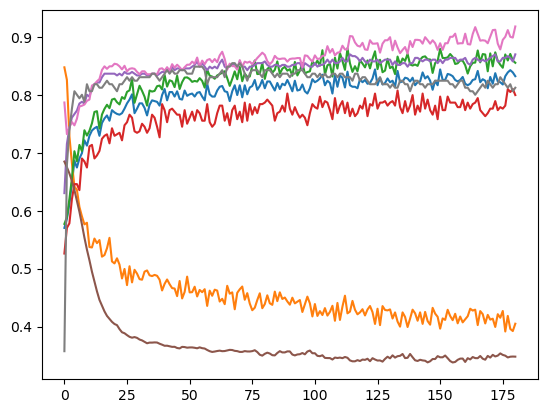

In [52]:
plt.plot(pd.DataFrame(model.history.history))
plt.show()

In [53]:
pred_proba = model.predict(X_test)
pred_classes = (pred_proba > 0.5).astype("int").flatten()

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [54]:
print(classification_report(y_test, pred_classes))
print(confusion_matrix(y_test, pred_classes))

              precision    recall  f1-score   support

           0       0.83      0.93      0.88       165
           1       0.92      0.81      0.86       165

    accuracy                           0.87       330
   macro avg       0.87      0.87      0.87       330
weighted avg       0.87      0.87      0.87       330

[[153  12]
 [ 31 134]]


In [55]:
# Best Result Yet
# Used feature engineerning
# Weights to balance classes(not much difference)
# SMOTE to balance class (Very effective)
# 3 Layers of Neural Network (32, 16, 8, 1)
# 0.3 Dropout layer for each layer
# stratify=y_sm in splitting, for equal distribution of classes in split
# random_state=15 in split, as less data

In [56]:
#Attempt to create pipeline for this project

from imblearn.pipeline import Pipeline